In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path(
    r"C:\Users\nhp\Documents\Palo_Alto_Career_Analytics\Data\Palo Alto Networks.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [7]:
print("CareerCluster" in df.columns)
print(df.shape)

False
(1470, 31)


In [8]:
print("df_model exists:", "df_model" in globals())

if "df_model" in globals():
    print("CareerCluster exists:", "CareerCluster" in df_model.columns)
    print("Shape:", df_model.shape)

df_model exists: False


In [7]:
print(df.columns.tolist())

['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   int64 
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EnvironmentSatisfaction   1470 non-null   int64 
 9   Gender                    1470 non-null   object
 10  HourlyRate                1470 non-null   int64 
 11  JobInvolvement            1470 non-null   int64 
 12  JobLevel                  1470 non-null   int64 
 13  JobRole                   1470 non-null   object
 14  JobSatisfaction         

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.00,60.0
Attrition,1470.0,0.161224,0.367863,0.0,0.0,0.0,0.00,1.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.0,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.0,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.0,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.0,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.0,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.0,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.0,2.0,3.00,5.0
JobSatisfaction,1470.0,2.728571,1.102846,1.0,2.0,3.0,4.00,4.0


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [11]:
missing = df.isnull().sum()

print(missing[missing > 0].sort_values(ascending=False))

Series([], dtype: int64)


In [12]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Calculate missing-value percentage
missing_percentage = (df.isnull().mean() * 100).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

# Display only columns with missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(by="Missing Percentage", ascending=False)

missing_summary

,Missing Values,Missing Percentage


In [13]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)

Total duplicate rows: 0


In [14]:
if duplicate_count > 0:
    df = df.drop_duplicates().copy()
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found.")

print("Dataset shape after duplicate check:", df.shape)

No duplicate rows found.
Dataset shape after duplicate check: (1470, 31)


In [15]:
# Check data types of all columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   int64 
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EnvironmentSatisfaction   1470 non-null   int64 
 9   Gender                    1470 non-null   object
 10  HourlyRate                1470 non-null   int64 
 11  JobInvolvement            1470 non-null   int64 
 12  JobLevel                  1470 non-null   int64 
 13  JobRole                   1470 non-null   object
 14  JobSatisfaction         

In [16]:

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.00,60.0
Attrition,1470.0,0.161224,0.367863,0.0,0.0,0.0,0.00,1.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.0,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.0,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.0,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.0,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.0,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.0,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.0,2.0,3.00,5.0
JobSatisfaction,1470.0,2.728571,1.102846,1.0,2.0,3.0,4.00,4.0


In [17]:

career_columns = [
    "Age",
    "Attrition",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "TrainingTimesLastYear"
]

available_columns = [
    col for col in career_columns if col in df.columns
]

print("Available career columns:", available_columns)


for col in available_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(10))

Available career columns: ['Age', 'Attrition', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'TrainingTimesLastYear']

Age:
Age
35    78
34    77
36    69
31    69
29    68
32    61
30    60
38    58
33    58
40    57
Name: count, dtype: int64

Attrition:
Attrition
0    1233
1     237
Name: count, dtype: int64

YearsAtCompany:
YearsAtCompany
5     196
1     171
3     128
2     127
10    120
4     110
7      90
9      82
8      80
6      76
Name: count, dtype: int64

YearsInCurrentRole:
YearsInCurrentRole
2    372
0    244
7    222
3    135
4    104
8     89
9     67
1     57
6     37
5     36
Name: count, dtype: int64

YearsSinceLastPromotion:
YearsSinceLastPromotion
0     581
1     357
2     159
7      76
4      61
3      52
5      45
6      32
11     24
8      18
Name: count, dtype: int64

TrainingTimesLastYear:
TrainingTimesLastYear
2    547
3    491
4    123
5    119
1     71
6     65
0     54
Name: count, dtype: int64


In [18]:
# Dataset overview
print("Total employees:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

df.head()

Total employees: 1470
Total columns: 31

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [19]:
if "Attrition" in df.columns:
    print(df["Attrition"].value_counts())

    print("\nAttrition percentage:")
    print(
        (df["Attrition"].value_counts(normalize=True) * 100).round(2)
    )
else:
    print("Attrition column is not available.")

Attrition
0    1233
1     237
Name: count, dtype: int64

Attrition percentage:
Attrition
0    83.88
1    16.12
Name: proportion, dtype: float64


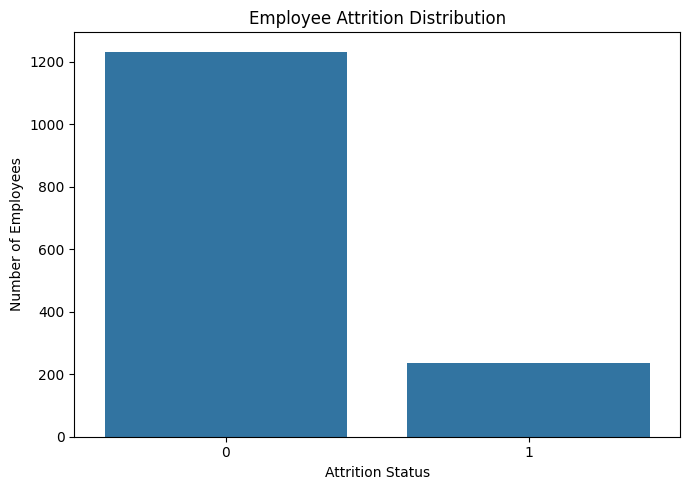

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

if "Attrition" in df.columns:
    plt.figure(figsize=(7, 5))

    sns.countplot(data=df, x="Attrition")

    plt.title("Employee Attrition Distribution")
    plt.xlabel("Attrition Status")
    plt.ylabel("Number of Employees")

    plt.tight_layout()
    plt.show()

In [21]:
promotion_columns = [
    "YearsSinceLastPromotion",
    "YearsAtCompany",
    "YearsInCurrentRole"
]

for col in promotion_columns:
    if col in df.columns:
        print(f"\n{col}")
        print(df[col].describe())
    else:
        print(f"\n{col}: Column not available")


YearsSinceLastPromotion
count    1470.000000
mean        2.187755
std         3.222430
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        15.000000
Name: YearsSinceLastPromotion, dtype: float64

YearsAtCompany
count    1470.000000
mean        7.008163
std         6.126525
min         0.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        40.000000
Name: YearsAtCompany, dtype: float64

YearsInCurrentRole
count    1470.000000
mean        4.229252
std         3.623137
min         0.000000
25%         2.000000
50%         3.000000
75%         7.000000
max        18.000000
Name: YearsInCurrentRole, dtype: float64


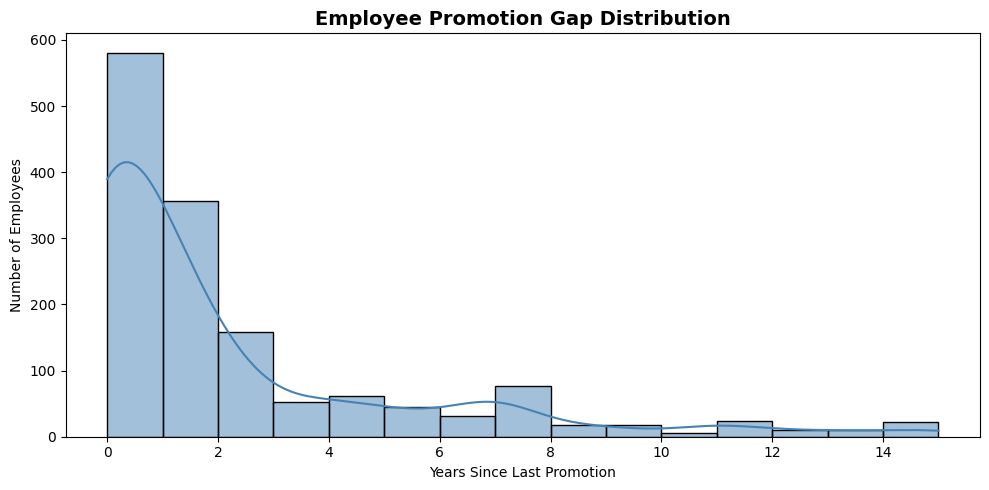

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

if "YearsSinceLastPromotion" in df.columns:
    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df,
        x="YearsSinceLastPromotion",
        bins=15,
        kde=True,
        color="steelblue"
    )

    plt.title("Employee Promotion Gap Distribution",
              fontsize=14, fontweight="bold")
    plt.xlabel("Years Since Last Promotion")
    plt.ylabel("Number of Employees")
    plt.tight_layout()
    plt.show()
else:
    print("YearsSinceLastPromotion column not found.")

In [23]:
import numpy as np

if "YearsSinceLastPromotion" in df.columns:
    df["PromotionGapCategory"] = np.select(
        [
            df["YearsSinceLastPromotion"] <= 2,
            df["YearsSinceLastPromotion"].between(3, 5),
            df["YearsSinceLastPromotion"] > 5
        ],
        [
            "0-2 Years",
            "3-5 Years",
            "6+ Years"
        ],
        default="Unknown"
    )

    print(df["PromotionGapCategory"].value_counts())

PromotionGapCategory
0-2 Years    1097
6+ Years      215
3-5 Years     158
Name: count, dtype: int64


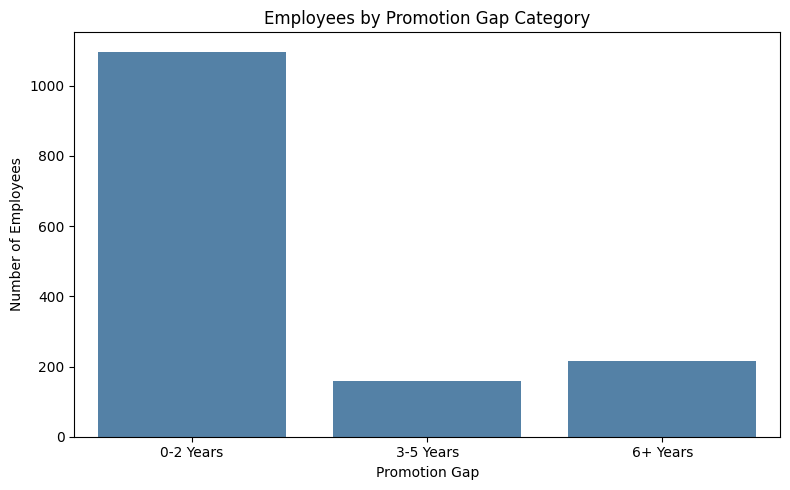

In [24]:
if "PromotionGapCategory" in df.columns:
    plt.figure(figsize=(8, 5))

    order = ["0-2 Years", "3-5 Years", "6+ Years"]

    sns.countplot(
        data=df,
        x="PromotionGapCategory",
        order=order,
        color="steelblue"
    )

    plt.title("Employees by Promotion Gap Category")
    plt.xlabel("Promotion Gap")
    plt.ylabel("Number of Employees")
    plt.tight_layout()
    plt.show()

In [4]:
# Overall dataset summary
print("===== DATASET OVERVIEW =====")
print(f"Total employee records: {len(df)}")
print(f"Total columns: {df.shape[1]}")

if "Department" in df.columns:
    print(f"Departments: {df['Department'].nunique()}")

if "Attrition" in df.columns:
    print("\n===== ATTRITION SUMMARY =====")
    print(df["Attrition"].value_counts())

    attrition_yes = (
        df["Attrition"].astype(str).str.strip().str.lower() == "yes"
    ).sum()

    valid_attrition = (
        df["Attrition"].astype(str).str.strip().str.lower().isin(["yes", "no"])
    ).sum()

    rate = (
        attrition_yes / valid_attrition * 100
        if valid_attrition > 0 else 0
    )

    print(f"Overall attrition rate: {rate:.2f}%")

if "YearsSinceLastPromotion" in df.columns:
    print("\n===== PROMOTION GAP SUMMARY =====")
    print(df["YearsSinceLastPromotion"].describe())

if "TrainingTimesLastYear" in df.columns:
    print("\n===== TRAINING SUMMARY =====")
    print(df["TrainingTimesLastYear"].describe())

if "CareerProgressionFlag" in df.columns:
    print("\n===== CAREER REVIEW SUMMARY =====")
    print(df["CareerProgressionFlag"].value_counts())

===== DATASET OVERVIEW =====
Total employee records: 1470
Total columns: 31
Departments: 3

===== ATTRITION SUMMARY =====
Attrition
0    1233
1     237
Name: count, dtype: int64
Overall attrition rate: 0.00%

===== PROMOTION GAP SUMMARY =====
count    1470.000000
mean        2.187755
std         3.222430
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        15.000000
Name: YearsSinceLastPromotion, dtype: float64

===== TRAINING SUMMARY =====
count    1470.000000
mean        2.799320
std         1.289271
min         0.000000
25%         2.000000
50%         3.000000
75%         3.000000
max         6.000000
Name: TrainingTimesLastYear, dtype: float64


In [5]:
insights = []

if "Attrition" in df.columns:
    attrition_labels = (
        df["Attrition"].astype(str).str.strip().str.lower()
    )
    valid = attrition_labels.isin(["yes", "no"])

    if valid.any():
        rate = (attrition_labels[valid] == "yes").mean() * 100
        insights.append({
            "Analysis": "Employee Attrition",
            "Finding": f"Observed attrition rate: {rate:.2f}%",
            "Business Implication": (
                "Use as a baseline for retention analysis."
            )
        })

if "YearsSinceLastPromotion" in df.columns:
    avg_gap = df["YearsSinceLastPromotion"].mean()

    insights.append({
        "Analysis": "Promotion Gap",
        "Finding": f"Average years since promotion: {avg_gap:.2f}",
        "Business Implication": (
            "Review long promotion gaps alongside role, tenure "
            "and performance information where available."
        )
    })

if "TrainingTimesLastYear" in df.columns:
    avg_training = df["TrainingTimesLastYear"].mean()

    insights.append({
        "Analysis": "Employee Training",
        "Finding": f"Average training sessions: {avg_training:.2f}",
        "Business Implication": (
            "Assess access to training and development opportunities."
        )
    })

if "CareerProgressionFlag" in df.columns:
    flagged = (df["CareerProgressionFlag"] == "Needs Career Review").sum()

    insights.append({
        "Analysis": "Career Progression",
        "Finding": f"Employees flagged for review: {flagged}",
        "Business Implication": (
            "Consider individualized career discussions; the flag "
            "is not proof of stagnation."
        )
    })

insights_df = pd.DataFrame(insights)
display(insights_df)

,Analysis,Finding,Business Implication
0,Promotion Gap,Average years since promotion: 2.19,"Review long promotion gaps alongside role, ten..."
1,Employee Training,Average training sessions: 2.80,Assess access to training and development oppo...


In [8]:
insights_df.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/eda_business_insights.csv",
    index=False
)

print("EDA insights saved successfully!")

EDA insights saved successfully!


In [9]:
required_columns = [
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "TrainingTimesLastYear"
]

for col in required_columns:
    if col in df.columns:
        print(f"Available: {col}")
    else:
        print(f"Missing: {col}")

Available: YearsAtCompany
Available: YearsInCurrentRole
Available: YearsSinceLastPromotion
Available: TrainingTimesLastYear


In [10]:
# Create a copy so the original analysis data remains unchanged
df_model = df.copy()

# Calculate the percentage of company tenure spent in the current role
if {"YearsAtCompany", "YearsInCurrentRole"}.issubset(df_model.columns):
    df_model["CurrentRoleTenureRatio"] = np.where(
        df_model["YearsAtCompany"] > 0,
        df_model["YearsInCurrentRole"] / df_model["YearsAtCompany"],
        np.nan
    )

# Flag employees for career progression review
if {"YearsInCurrentRole", "YearsSinceLastPromotion"}.issubset(df_model.columns):
    df_model["CareerReviewFlag"] = np.where(
        (df_model["YearsInCurrentRole"] >= 3) &
        (df_model["YearsSinceLastPromotion"] >= 3),
        1,
        0
    )

print("New career progression features created.")

df_model.head()

New career progression features created.


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,CurrentRoleTenureRatio,CareerReviewFlag
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,0,8,0,1,6,4,0,5,0.666667,0
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,1,10,3,3,10,7,1,7,0.700000,0
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,0,7,3,3,0,0,0,0,NaN,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,0,8,3,3,8,7,3,0,0.875000,1
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,1,6,3,3,2,2,2,2,1.000000,0


In [11]:
feature_columns = [
    "CurrentRoleTenureRatio",
    "CareerReviewFlag"
]

for col in feature_columns:
    if col in df_model.columns:
        print(f"\n{col}")
        print(df_model[col].describe())


CurrentRoleTenureRatio
count    1426.000000
mean        0.596061
std         0.320877
min         0.000000
25%         0.400000
50%         0.666667
75%         0.845142
max         1.000000
Name: CurrentRoleTenureRatio, dtype: float64

CareerReviewFlag
count    1470.000000
mean        0.229932
std         0.420932
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: CareerReviewFlag, dtype: float64


In [12]:
df_model.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/Palo_Alto_Career_Engineered.csv",
    index=False
)

print("Feature-engineered dataset saved successfully!")

Feature-engineered dataset saved successfully!


In [13]:
# Select numerical features for career progression clustering

candidate_features = [
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "TrainingTimesLastYear",
    "CurrentRoleTenureRatio"
]

features = [
    col for col in candidate_features
    if col in df_model.columns
]

print("Selected features:", features)
print("Number of features:", len(features))

Selected features: ['YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'TrainingTimesLastYear', 'CurrentRoleTenureRatio']
Number of features: 5


In [14]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Extract selected features
X = df_model[features].copy()

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values with the median of each feature
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

print("Missing values after imputation:",
      np.isnan(X_imputed).sum())

Missing values after imputation: 0


In [15]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

print("Scaled data shape:", X_scaled.shape)
print("Mean of first feature:", round(X_scaled[:, 0].mean(), 4))
print("Standard deviation of first feature:",
      round(X_scaled[:, 0].std(), 4))

Scaled data shape: (1470, 5)
Mean of first feature: -0.0
Standard deviation of first feature: 1.0


In [18]:
import os

os.makedirs("C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/", exist_ok=True)

scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df_model.index
)

scaled_df.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/Palo_Alto_ML_Features.csv",
    index=False
)

print("Machine learning features saved successfully!")

Machine learning features saved successfully!


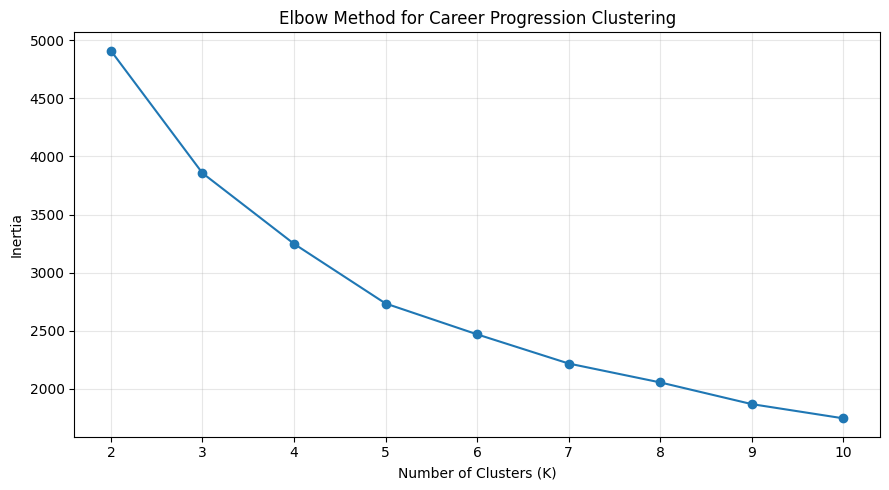

In [19]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(k_values, inertia_values, marker="o")

plt.title("Elbow Method for Career Progression Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import silhouette_score

silhouette_results = []

for k in range(2, min(11, len(X_scaled))):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_results.append({
        "Clusters": k,
        "Silhouette Score": round(score, 4)
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(
    silhouette_df.sort_values(
        by="Silhouette Score",
        ascending=False
    )
)

,Clusters,Silhouette Score
0,2,0.3364
4,6,0.3260
3,5,0.3193
5,7,0.3153
2,4,0.3096
1,3,0.2976
8,10,0.2967
7,9,0.2871
6,8,0.2808


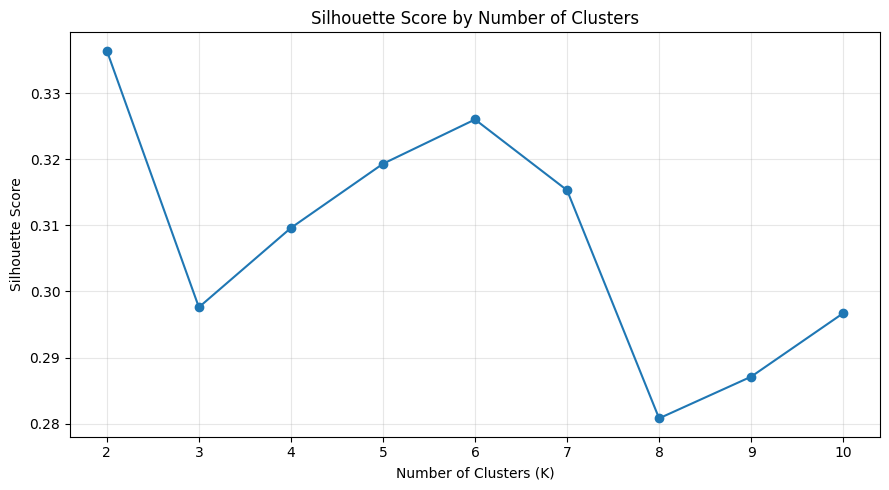

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(
    silhouette_df["Clusters"],
    silhouette_df["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(silhouette_df["Clusters"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
best_k = int(
    silhouette_df.loc[
        silhouette_df["Silhouette Score"].idxmax(),
        "Clusters"
    ]
)

print("Best K based on silhouette score:", best_k)

Best K based on silhouette score: 2


In [23]:
from sklearn.cluster import KMeans

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df_model["CareerCluster"] = final_kmeans.fit_predict(X_scaled)

print("K-Means model trained successfully!")
print("\nEmployees in each cluster:")
print(df_model["CareerCluster"].value_counts().sort_index())

K-Means model trained successfully!

Employees in each cluster:
CareerCluster
0    535
1    935
Name: count, dtype: int64


In [24]:
cluster_features = [
    col for col in features
    if col in df_model.columns
]

cluster_profile = (
    df_model.groupby("CareerCluster")[cluster_features]
    .mean()
    .round(2)
)

display(cluster_profile)

,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,TrainingTimesLastYear,CurrentRoleTenureRatio
CareerCluster,,,,,
0,12.8,8.32,4.57,2.81,0.73
1,3.7,1.89,0.82,2.79,0.51


In [25]:
cluster_sizes = (
    df_model["CareerCluster"]
    .value_counts()
    .sort_index()
    .rename_axis("CareerCluster")
    .reset_index(name="EmployeeCount")
)

cluster_sizes["Percentage"] = (
    cluster_sizes["EmployeeCount"] / len(df_model) * 100
).round(2)

display(cluster_sizes)


,CareerCluster,EmployeeCount,Percentage
0,0,535,36.39
1,1,935,63.61


In [27]:
import os

os.makedirs("C:/Users/nhp/Documents/Palo_Alto_Career_Analytics", exist_ok=True)
os.makedirs("C:/Users/nhp/Documents/Palo_Alto_Career_Analytics", exist_ok=True)

cluster_profile.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/career_cluster_profiles.csv"
)

cluster_sizes.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/career_cluster_sizes.csv",
    index=False
)

df_model.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/Palo_Alto_Career_Clustered.csv",
    index=False
)

print("Cluster profiles, sizes, and employee data saved successfully!")


Cluster profiles, sizes, and employee data saved successfully!


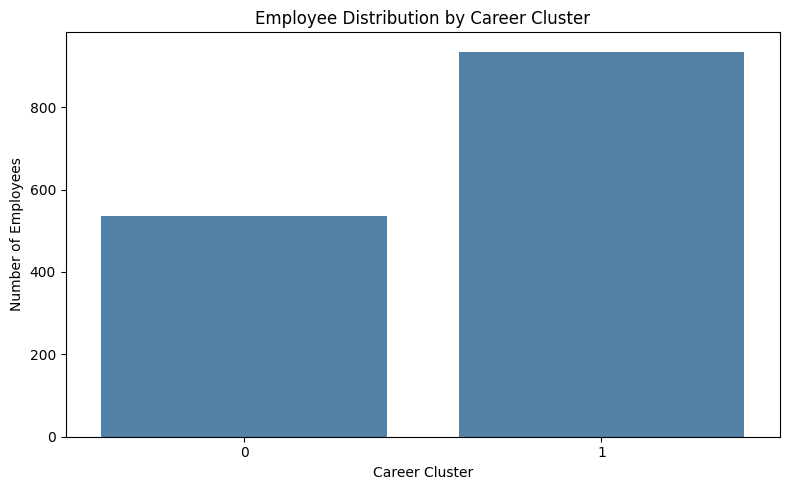

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_model,
    x="CareerCluster",
    color="steelblue"
)

plt.title("Employee Distribution by Career Cluster")
plt.xlabel("Career Cluster")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

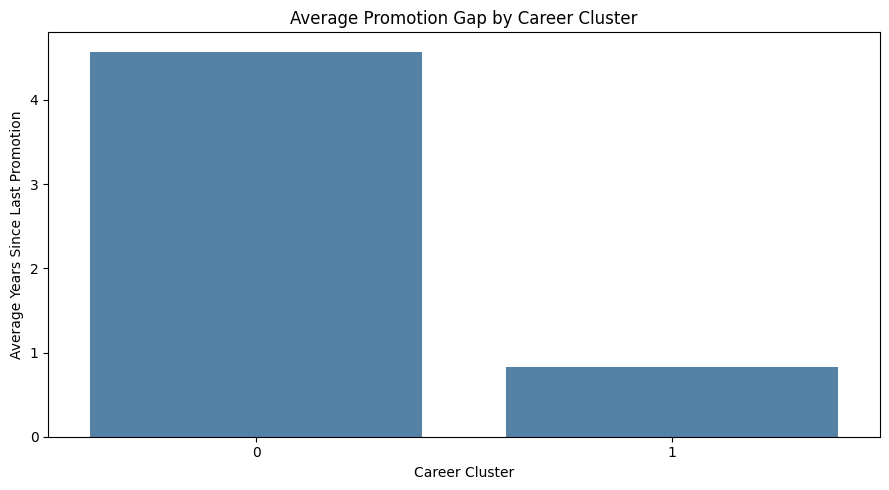

In [29]:

if "YearsSinceLastPromotion" in df_model.columns:

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=df_model,
        x="CareerCluster",
        y="YearsSinceLastPromotion",
        errorbar=None,
        color="steelblue"
    )

    plt.title("Average Promotion Gap by Career Cluster")
    plt.xlabel("Career Cluster")
    plt.ylabel("Average Years Since Last Promotion")
    plt.tight_layout()
    plt.show()


In [30]:
cluster_summary = (
    df_model.groupby("CareerCluster")
    .agg(
        Employee_Count=("CareerCluster", "size"),
        Avg_Company_Tenure=("YearsAtCompany", "mean"),
        Avg_Current_Role_Years=("YearsInCurrentRole", "mean"),
        Avg_Years_Since_Promotion=("YearsSinceLastPromotion", "mean"),
        Avg_Training_Sessions=("TrainingTimesLastYear", "mean")
    )
    .round(2)
)

display(cluster_summary)

,Employee_Count,Avg_Company_Tenure,Avg_Current_Role_Years,Avg_Years_Since_Promotion,Avg_Training_Sessions
CareerCluster,,,,,
0,535,12.8,8.32,4.57,2.81
1,935,3.7,1.89,0.82,2.79


In [32]:
import os

os.makedirs("C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/reports", exist_ok=True)

cluster_summary.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/reports/career_cluster_interpretation.csv"
)

print("Cluster interpretation report saved.")

Cluster interpretation report saved.


In [33]:
if "Attrition" in df_model.columns:
    print(df_model["Attrition"].value_counts(dropna=False))
else:
    print("Attrition column is not available.")

Attrition
0    1233
1     237
Name: count, dtype: int64


In [34]:
# Normalize attrition labels
attrition_labels = (
    df_model["Attrition"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Keep recognized Yes/No records for rate calculations
valid = attrition_labels.isin(["yes", "no"])

attrition_data = df_model.loc[valid].copy()
attrition_data["AttritionBinary"] = (
    attrition_labels.loc[valid] == "yes"
).astype(int)

# Calculate cluster-level metrics
cluster_attrition = (
    attrition_data.groupby("CareerCluster")
    .agg(
        Employees=("AttritionBinary", "size"),
        Employees_Left=("AttritionBinary", "sum"),
        Attrition_Rate=("AttritionBinary", "mean")
    )
)

cluster_attrition["Attrition_Rate_Percent"] = (
    cluster_attrition["Attrition_Rate"] * 100
).round(2)

display(cluster_attrition)

,Employees,Employees_Left,Attrition_Rate,Attrition_Rate_Percent
CareerCluster,,,,


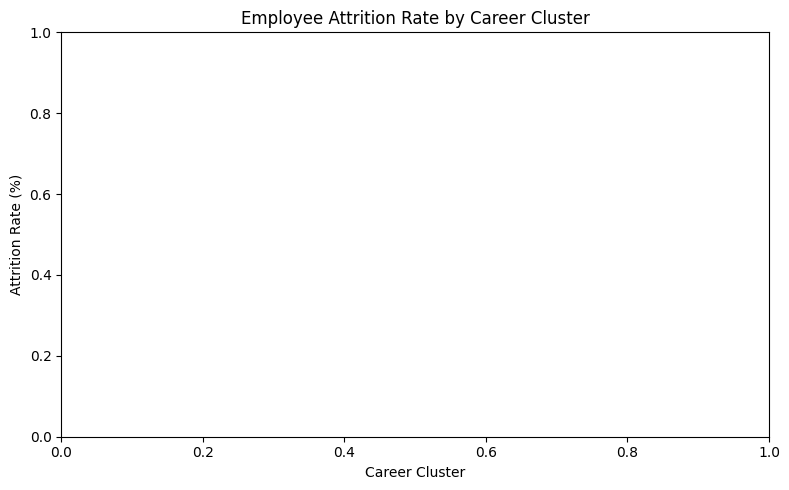

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = cluster_attrition.reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_data,
    x="CareerCluster",
    y="Attrition_Rate_Percent",
    color="steelblue"
)

plt.title("Employee Attrition Rate by Career Cluster")
plt.xlabel("Career Cluster")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

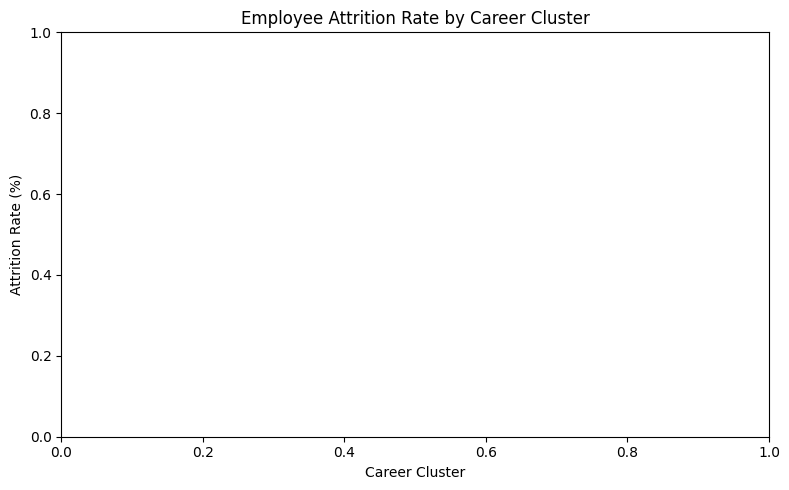

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = cluster_attrition.reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_data,
    x="CareerCluster",
    y="Attrition_Rate_Percent",
    color="steelblue"
)

plt.title("Employee Attrition Rate by Career Cluster")
plt.xlabel("Career Cluster")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

In [48]:
import os

os.makedirs("C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/reports", exist_ok=True)

cluster_attrition.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/reports/cluster_attrition_analysis.csv"
)

print("Cluster attrition analysis saved successfully!")

Cluster attrition analysis saved successfully!


In [49]:
import numpy as np
import pandas as pd

# Recreate the promotion-gap category in df_model
if "YearsSinceLastPromotion" in df_model.columns:

    df_model["PromotionGapCategory"] = np.select(
        [
            df_model["YearsSinceLastPromotion"] <= 2,
            df_model["YearsSinceLastPromotion"].between(3, 5),
            df_model["YearsSinceLastPromotion"] > 5
        ],
        [
            "0-2 Years",
            "3-5 Years",
            "6+ Years"
        ],
        default="Unknown"
    )

    print("PromotionGapCategory created successfully!")
    print(df_model["PromotionGapCategory"].value_counts())

else:
    print("YearsSinceLastPromotion column is missing.")

PromotionGapCategory created successfully!
PromotionGapCategory
0-2 Years    1097
6+ Years      215
3-5 Years     158
Name: count, dtype: int64


In [50]:
# Recreate the cleaned attrition dataset
df_model["AttritionClean"] = (
    df_model["Attrition"]
    .astype("string")
    .str.strip()
    .str.lower()
)

valid_df = df_model[
    df_model["AttritionClean"].isin(["yes", "no"])
].copy()

valid_df["Left"] = (
    valid_df["AttritionClean"] == "yes"
).astype(int)

# Analyze attrition by promotion gap
attrition_by_promotion = (
    valid_df.groupby("PromotionGapCategory")
    .agg(
        Employees=("Left", "size"),
        Employees_Left=("Left", "sum"),
        Attrition_Rate=("Left", "mean")
    )
)

attrition_by_promotion["Attrition_Rate_Percent"] = (
    attrition_by_promotion["Attrition_Rate"] * 100
).round(2)

display(attrition_by_promotion)

,Employees,Employees_Left,Attrition_Rate,Attrition_Rate_Percent
PromotionGapCategory,,,,


In [51]:


# Normalize attrition labels
df_model["AttritionClean"] = (
    df_model["Attrition"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Keep only recognized Yes/No labels
valid_df = df_model[
    df_model["AttritionClean"].isin(["yes", "no"])
].copy()

valid_df["Left"] = (
    valid_df["AttritionClean"] == "yes"
).astype(int)

# Calculate attrition by promotion-gap category
attrition_by_promotion = (
    valid_df.groupby("PromotionGapCategory")
    .agg(
        Employees=("Left", "size"),
        Employees_Left=("Left", "sum"),
        Attrition_Rate=("Left", "mean")
    )
)

attrition_by_promotion["Attrition_Rate_Percent"] = (
    attrition_by_promotion["Attrition_Rate"] * 100
).round(2)

display(attrition_by_promotion)

,Employees,Employees_Left,Attrition_Rate,Attrition_Rate_Percent
PromotionGapCategory,,,,


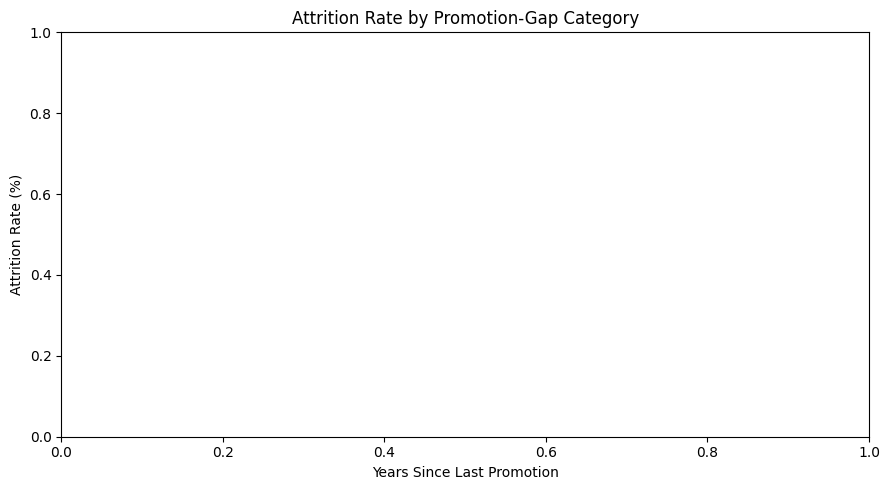

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = attrition_by_promotion.reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_df,
    x="PromotionGapCategory",
    
    y="Attrition_Rate_Percent",
    color="steelblue"
)

plt.title("Attrition Rate by Promotion-Gap Category")
plt.xlabel("Years Since Last Promotion")
plt.ylabel("Attrition Rate (%)")
plt.tight_layout()
plt.show()

In [46]:
if "Department" in valid_df.columns:

    department_attrition = (
        valid_df.groupby("Department")
        .agg(
            Employees=("Left", "size"),
            Employees_Left=("Left", "sum"),
            Attrition_Rate=("Left", "mean")
        )
    )

    department_attrition["Attrition_Rate_Percent"] = (
        department_attrition["Attrition_Rate"] * 100
    ).round(2)

    display(
        department_attrition.sort_values(
            "Attrition_Rate_Percent",
            ascending=False
        )
    )
else:
    print("Department column is not available.")

,Employees,Employees_Left,Attrition_Rate,Attrition_Rate_Percent
Department,,,,


In [56]:
import os

os.makedirs("C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/reports", exist_ok=True)

attrition_by_promotion.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/reports/attrition_by_promotion_gap.csv"
)

if "Department" in valid_df.columns:
    department_attrition.to_csv(
        "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/reports/attrition_by_department.csv"
    )

print("Attrition analysis reports saved successfully!")

Attrition analysis reports saved successfully!


In [57]:
# Review attrition by promotion-gap category
display(attrition_by_promotion)

# Review attrition by department
if "Department" in valid_df.columns:
    display(department_attrition)

# Review employee career clusters
display(cluster_summary)

,Employees,Employees_Left,Attrition_Rate,Attrition_Rate_Percent
PromotionGapCategory,,,,


,Employees,Employees_Left,Attrition_Rate,Attrition_Rate_Percent
Department,,,,


,Employee_Count,Avg_Company_Tenure,Avg_Current_Role_Years,Avg_Years_Since_Promotion,Avg_Training_Sessions
CareerCluster,,,,,
0,535,12.8,8.32,4.57,2.81
1,935,3.7,1.89,0.82,2.79


In [58]:
recommendations = pd.DataFrame([
    {
        "Finding Area": "Long Promotion Gaps",
        "Potential Concern": "Employees may have limited visible career progression.",
        "Recommended Action": "Review promotion criteria, career plans, and progression opportunities."
    },
    {
        "Finding Area": "Department Attrition",
        "Potential Concern": "Some departments may show higher observed attrition rates.",
        "Recommended Action": "Investigate workload, management practices, compensation, and development opportunities."
    },
    {
        "Finding Area": "Career Clusters",
        "Potential Concern": "Employee groups may show different tenure and promotion patterns.",
        "Recommended Action": "Offer tailored career discussions and development plans based on employee needs."
    },
    {
        "Finding Area": "Training Opportunities",
        "Potential Concern": "Training participation may differ across employees.",
        "Recommended Action": "Review access to relevant learning, mentoring, and skill-development opportunities."
    }
])

display(recommendations)

,Finding Area,Potential Concern,Recommended Action
0,Long Promotion Gaps,Employees may have limited visible career prog...,"Review promotion criteria, career plans, and p..."
1,Department Attrition,Some departments may show higher observed attr...,"Investigate workload, management practices, co..."
2,Career Clusters,Employee groups may show different tenure and ...,Offer tailored career discussions and developm...
3,Training Opportunities,Training participation may differ across emplo...,"Review access to relevant learning, mentoring,..."


In [61]:
import os

os.makedirs("C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/reports", exist_ok=True)

recommendations.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/reports/hr_retention_recommendations.csv",
    index=False
)

print("HR recommendations saved successfully!")

HR recommendations saved successfully!


In [63]:
df_model.to_csv(
    "C:/Users/nhp/Documents/Palo_Alto_Career_Analytics/Palo_Alto_Final_Analysis.csv",
    index=False
)

print("Final analysis dataset saved successfully!")

Final analysis dataset saved successfully!
